In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.validation import fixed_split_forecast, score_table, monthly_mae
from src.controllers import controller_a, controller_b, controller_plan
from src.dispatch import annual_bill

HORIZON = 72
df = pd.read_csv(ROOT / "data" / "processed" / "features_h72.csv", index_col=0, parse_dates=True)
fixed = fixed_split_forecast(df, HORIZON, test_start="2025-10-01")
fixed.to_csv(ROOT / "results" / "fixed_split_h72.csv")

wf = pd.read_csv(ROOT / "results" / "walk_forward_h72.csv", index_col=0, parse_dates=True)
assert wf.index.equals(fixed.index), "the two methods must be tested on the same hours"
assert np.allclose(wf["actual"], fixed["actual"])
train_days = round(len(df[df.index <= pd.Timestamp("2025-10-01") - pd.Timedelta(hours=HORIZON)]) / 24)
print(f"Fixed split trains once on {train_days} days; both methods are tested on {len(fixed)} hours.")

Fixed split trains once on 287 days; both methods are tested on 8616 hours.


In [2]:
models = ["Linear regression", "Decision tree", "SVR"]
fixed["Baseline"] = wf["baseline"]
wf_scores = score_table(wf, ["baseline"] + models)
wf_scores.index = ["Baseline"] + models
fx_scores = score_table(fixed, ["Baseline"] + models)
accuracy = pd.concat({"Walk-forward": wf_scores, "Fixed split": fx_scores}, axis=1)
accuracy.round(2).to_csv(ROOT / "results" / "validation_comparison_accuracy.csv")
print(accuracy.round(2).to_string())
print(f"\nSVR MAE is {100*(1-fx_scores.loc['SVR','MAE']/fx_scores.loc['Baseline','MAE']):.0f}% below the baseline (fixed split) "
      f"and {100*(1-wf_scores.loc['SVR','MAE']/wf_scores.loc['Baseline','MAE']):.0f}% below it (walk-forward).")

                  Walk-forward                Fixed split               
                           MAE    RMSE   Bias         MAE    RMSE   Bias
Baseline                 53.78   91.00   0.07       53.78   91.00   0.07
Linear regression        45.04   69.43  18.51       53.68   78.19  23.53
Decision tree            43.31  115.69  27.68       50.97  125.02  37.80
SVR                      31.72   56.09  15.65       38.18   61.03  23.87

SVR MAE is 29% below the baseline (fixed split) and 41% below it (walk-forward).


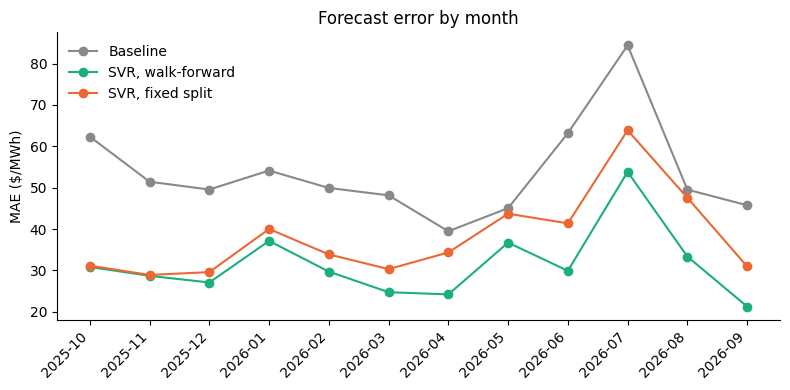

In [3]:
walk_m, fixed_m = monthly_mae(wf, "SVR"), monthly_mae(fixed, "SVR")
base_m = monthly_mae(wf, "baseline")

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(walk_m))
ax.plot(x, base_m.values, color="#8a8985", marker="o", label="Baseline")
ax.plot(x, walk_m.values, color="#1baf7a", marker="o", label="SVR, walk-forward")
ax.plot(x, fixed_m.values, color="#eb6834", marker="o", label="SVR, fixed split")
ax.set_xticks(x)
ax.set_xticklabels([str(p) for p in walk_m.index], rotation=45, ha="right")
ax.set_ylabel("MAE ($/MWh)")
ax.set_title("Forecast error by month")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(ROOT / "results" / "fig_validation_comparison.png", dpi=150)
plt.show()

In [4]:
fc = pd.read_csv(ROOT / "results" / "forecasts.csv", index_col=0, parse_dates=True)
pv = pd.read_csv(ROOT / "data" / "processed" / "pv_hourly.csv", index_col=0, parse_dates=True)["pv_kwh"]
load = pd.read_csv(ROOT / "data" / "processed" / "household_load_hourly.csv",
                   index_col=0, parse_dates=True)["load_kwh"]
spot, days = fc["price_actual_mwh"].values, len(fc) / 24
bill = lambda r: annual_bill(r["import_kwh"], r["export_kwh"], spot, days)["total"]

bills = pd.Series({
    "A  No battery": bill(controller_a(pv, load)),
    "B  Simple rule": bill(controller_b(pv, load)),
    "C  SVR forecast, walk-forward": bill(controller_plan(pv, load, wf["SVR"].reindex(fc.index).values)),
    "C  SVR forecast, fixed split": bill(controller_plan(pv, load, fixed["SVR"].reindex(fc.index).values)),
    "D  Perfect foresight": bill(controller_plan(pv, load, spot)),
}, name="Annual bill ($)")

d = bills["D  Perfect foresight"]
table = pd.DataFrame({"Annual bill ($)": bills,
                      "Saving vs A ($)": bills["A  No battery"] - bills,
                      "Forecast error cost vs D ($)": bills - d})
table.loc[["A  No battery", "B  Simple rule", "D  Perfect foresight"], "Forecast error cost vs D ($)"] = np.nan
table.round(2).to_csv(ROOT / "results" / "validation_comparison_bills.csv")
table.round(2)

,Annual bill ($),Saving vs A ($),Forecast error cost vs D ($)
A No battery,1179.84,0.00,NaN
B Simple rule,643.46,536.38,NaN
"C SVR forecast, walk-forward",590.75,589.08,44.62
"C SVR forecast, fixed split",591.73,588.11,45.60
D Perfect foresight,546.13,633.70,NaN
